# Un percettrone da zero, con Gemini · soluzione
**La logica della rete: come pensa una rete neurale** · Incontro 1

Il codice lo scrive **Gemini**, l'assistente di Colab. Il nostro lavoro è chiedere bene e controllare il risultato.

| | |
|---|---|
| **1 · Chiedi chiaro** | che cosa vuoi, con quali dati, in che forma vuoi il risultato |
| **2 · Leggi** | il codice proposto, anche senza capirlo tutto: quali dati usa? che cosa calcola? |
| **3 · Esegui** | e guarda che cosa succede, errori compresi |
| **4 · Controlla** | il risultato torna con quello che sai? I pesi sono quelli della scheda? |

> **Prima di tutto:** *File → Salva una copia in Drive*, poi lavorate sulla vostra copia.

> **Versione per il docente.** Ogni tappa ha una soluzione possibile, già eseguita. Gemini scriverà codice
> diverso: va bene, conta che i risultati tornino con la scheda.

## Come chiedere a Gemini
1. In una cella di codice vuota, cliccate su **genera** (oppure aprite il pannello di Gemini, in alto a destra).
2. Scrivete la richiesta in italiano: potete copiare il prompt di esempio.
3. Leggete il codice proposto prima di accettarlo, poi eseguitelo con ▶.

*Se Gemini non è disponibile:* usate ChatGPT o Claude in un'altra scheda e incollate qui il codice.

## Tappa 1 · Il percettrone da zero
**Prompt di esempio:**

> Crea con pandas una tabella con 6 serate e le colonne piove, amici, verifica ed esco (1 = sì, 0 = no):
> 0,1,0,1 · 1,1,0,1 · 0,0,0,0 · 0,1,1,0 · 1,0,0,0 · 1,1,1,0.
> Poi scrivi un percettrone da zero, senza librerie di machine learning: pesi e bias a 0, funzione a gradino
> (1 se z ≥ 0), regola di apprendimento con η = 1. Allenalo finché non sbaglia più e stampa pesi e bias dopo ogni serata.

In [1]:
import pandas as pd

# le sei serate della scheda: 1 = sì, 0 = no
serate = pd.DataFrame({
    "piove":    [0, 1, 0, 0, 1, 1],
    "amici":    [1, 1, 0, 1, 0, 1],
    "verifica": [0, 0, 0, 1, 0, 1],
    "esco":     [1, 1, 0, 0, 0, 0],
}, index=[1, 2, 3, 4, 5, 6])
serate

,piove,amici,verifica,esco
1,0,1,0,1
2,1,1,0,1
3,0,0,0,0
4,0,1,1,0
5,1,0,0,0
6,1,1,1,0


In [2]:
# il percettrone da zero: pesi e bias a 0, funzione a gradino, regola di apprendimento con eta = 1
X = serate[["piove", "amici", "verifica"]].values.tolist()
y = serate["esco"].values.tolist()
w = [0, 0, 0]
b = 0
eta = 1

for giro in range(1, 21):
    errori = 0
    for x_i, y_i, sera in zip(X, y, serate.index):
        z = sum(w_j * x_j for w_j, x_j in zip(w, x_i)) + b
        previsione = 1 if z >= 0 else 0
        if previsione != y_i:
            errori += 1
            w = [w_j + eta * (y_i - previsione) * x_j for w_j, x_j in zip(w, x_i)]
            b = b + eta * (y_i - previsione)
        print(f"giro {giro}, sera {sera}: z = {z:+d}, previsione {previsione}, vera {y_i}  ->  pesi {w}, bias {b}")
    print(f"--- fine del giro {giro}: {errori} errori\n")
    if errori == 0:
        break

print("Pesi finali:", w, " bias:", b)

giro 1, sera 1: z = +0, previsione 1, vera 1  ->  pesi [0, 0, 0], bias 0
giro 1, sera 2: z = +0, previsione 1, vera 1  ->  pesi [0, 0, 0], bias 0
giro 1, sera 3: z = +0, previsione 1, vera 0  ->  pesi [0, 0, 0], bias -1
giro 1, sera 4: z = -1, previsione 0, vera 0  ->  pesi [0, 0, 0], bias -1
giro 1, sera 5: z = -1, previsione 0, vera 0  ->  pesi [0, 0, 0], bias -1
giro 1, sera 6: z = -1, previsione 0, vera 0  ->  pesi [0, 0, 0], bias -1
--- fine del giro 1: 1 errori

giro 2, sera 1: z = -1, previsione 0, vera 1  ->  pesi [0, 1, 0], bias 0
giro 2, sera 2: z = +1, previsione 1, vera 1  ->  pesi [0, 1, 0], bias 0
giro 2, sera 3: z = +0, previsione 1, vera 0  ->  pesi [0, 1, 0], bias -1
giro 2, sera 4: z = +0, previsione 1, vera 0  ->  pesi [0, 0, -1], bias -2
giro 2, sera 5: z = -2, previsione 0, vera 0  ->  pesi [0, 0, -1], bias -2
giro 2, sera 6: z = -3, previsione 0, vera 0  ->  pesi [0, 0, -1], bias -2
--- fine del giro 2: 3 errori

giro 3, sera 1: z = -2, previsione 0, vera 1  ->  p

**Controllate**
- I pesi finali sono (0, 1, −1) con bias −1, dopo 4 giri? Sono gli stessi della scheda?
- Dove, nel codice, c'è la regola di apprendimento? E la funzione a gradino?
- Se Gemini usa `Perceptron` di scikit-learn, chiedete di riscriverlo senza: vogliamo vedere la regola.

**Che cosa si deve vedere:** errori per giro 1, 3, 1, 0. Pesi finali (0, 1, −1), bias −1: la pioggia non
conta, gli amici spingono verso il sì, la verifica verso il no. È la stessa traccia della guida per il docente.

## Tappa 2 · Guardarlo imparare
**Prompt di esempio:**

> Fissa piove = 0 e disegna nel piano amici–verifica le quattro serate possibili, colorate per «esco» o «resto»,
> e la zona in cui il percettrone dice «esco» dopo ognuno dei primi 4 giri.

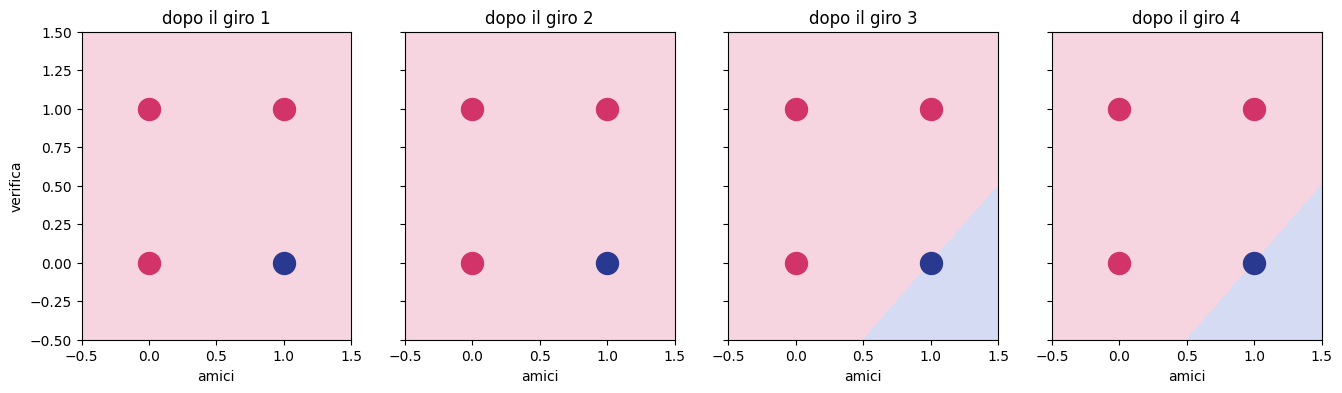

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def allena(X, y, giri):
    """restituisce pesi e bias alla fine di ogni giro"""
    w, b, storia = np.zeros(X.shape[1]), 0.0, []
    for _ in range(giri):
        for x_i, y_i in zip(X, y):
            previsione = 1 if w @ x_i + b >= 0 else 0
            w = w + (y_i - previsione) * x_i
            b = b + (y_i - previsione)
        storia.append((w.copy(), b))
    return storia

storia = allena(np.array(X), np.array(y), 4)
punti = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])          # (amici, verifica), con piove = 0
esco = [0, 1, 0, 0]
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))

fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for giro, (ax, (w, b)) in enumerate(zip(axs, storia), 1):
    z = w[1] * xx + w[2] * yy + b                            # piove = 0
    ax.contourf(xx, yy, z >= 0, levels=[-0.5, 0.5, 1.5], colors=["#F6D5E0", "#D5DBF2"])
    for (a, v), e in zip(punti, esco):
        ax.scatter(a, v, s=250, color="#2A3990" if e else "#D23369", zorder=3)
    ax.set_title(f"dopo il giro {giro}")
    ax.set_xlabel("amici")
axs[0].set_ylabel("verifica")
plt.show()

**Domande**
- Come si sposta il confine da un giro all'altro?
- Perché il confine è sempre una retta? Quante rette diverse andrebbero bene?

## Tappa 3 · Il limite: lo XOR
**Prompt di esempio:**

> Ora allena lo stesso percettrone sullo XOR: esco se c'è solo uno tra Anna e Bruno (0,0 → 0; 1,0 → 1; 0,1 → 1;
> 1,1 → 0). Fai 20 giri e stampa quanti errori fa in ogni giro, poi disegna i quattro punti.

Errori per giro: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


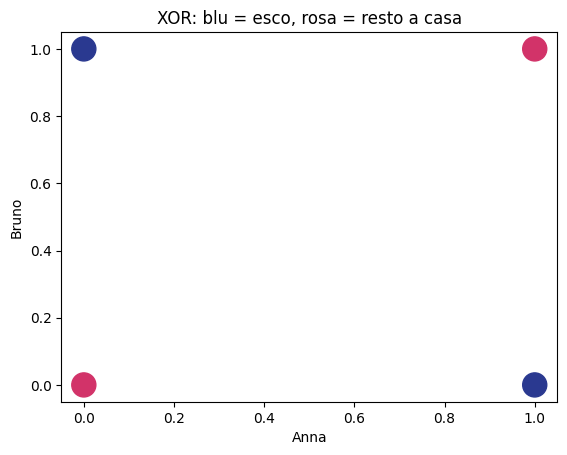

In [4]:
# XOR: esco se c'è solo uno tra Anna e Bruno
X_xor = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

w, b = np.zeros(2), 0.0
errori_per_giro = []
for giro in range(20):
    errori = 0
    for x_i, y_i in zip(X_xor, y_xor):
        previsione = 1 if w @ x_i + b >= 0 else 0
        if previsione != y_i:
            errori += 1
            w = w + (y_i - previsione) * x_i
            b = b + (y_i - previsione)
    errori_per_giro.append(errori)
print("Errori per giro:", errori_per_giro)

plt.scatter(X_xor[:, 0], X_xor[:, 1], c=["#D23369", "#2A3990", "#2A3990", "#D23369"], s=300)
plt.xlabel("Anna"); plt.ylabel("Bruno"); plt.title("XOR: blu = esco, rosa = resto a casa")
plt.show()

**Controllate:** 3 o 4 errori a ogni giro, senza mai arrivare a 0. Nel grafico, i due «esco» stanno su
una diagonale: nessuna retta li separa dagli altri due.

## Sfida · Uno strato nascosto
**Prompt di esempio:**

> Usa MLPClassifier di scikit-learn con uno strato nascosto di 4 neuroni, attivazione tanh, solver lbfgs e
> random_state=0 per imparare lo XOR, e mostrami le previsioni sui quattro casi.

In [5]:
from sklearn.neural_network import MLPClassifier

# una rete con uno strato nascosto di 4 neuroni
rete = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs", random_state=0, max_iter=2000)
rete.fit(X_xor, y_xor)
print("Previsioni:", rete.predict(X_xor), " risposte giuste:", y_xor)

Previsioni: [0 1 1 0]  risposte giuste: [0 1 1 0]


**Controllate:** le quattro previsioni coincidono con le risposte giuste (0, 1, 1, 0)?
- Gemini ha usato davvero tanh, lbfgs e random_state=0? Con i valori predefiniti di scikit-learn la rete di solito
  non impara lo XOR.
- Se le previsioni non tornano, cambiate random_state: perché il risultato dipende da questo numero lo vediamo
  nell'incontro 2.

**Che cosa si deve vedere:** con uno strato nascosto le previsioni coincidono con le risposte giuste.
Come fa la rete a trovare i pesi dello strato nascosto? Con la backpropagation: è l'incontro 2.

*Per il docente:* su 20 valori di random_state, con 4 neuroni tanh e lbfgs la rete impara lo XOR 20 volte su 20;
con 2 neuroni 14 su 20; con i valori predefiniti (relu, adam) 0 su 20, sia con 2 sia con 4 neuroni.

## Per finire
Avete scritto e allenato un neurone artificiale, visto il suo confine di decisione e il suo limite. **Nell'incontro 2**
reti con più strati e milioni di pesi: come impara una rete quando la regola del percettrone non basta più.